# LGG Segmentation Dataset

This dataset contains brain MR images together with manual FLAIR abnormality segmentation masks. The images were obtained from The Cancer Imaging Archive (TCIA). They correspond to 110 patients included in The Cancer Genome Atlas (TCGA) lower-grade glioma collection with at least fluid-attenuated inversion recovery (FLAIR) sequence and genomic cluster data available. Tumor genomic clusters and patient data is provided in data.csv file.

All images are provided in `.tif` format with 3 channels per image. 
1. For 101 cases, 3 sequences are available, i.e. pre-contrast, FLAIR, post-contrast (in this order of channels).
2. For 9 cases, post-contrast sequence is missing.
3. For 6 cases, pre-contrast sequence is missing.
4. Missing sequences are replaced with FLAIR sequence to make all images 3-channel.
5. Masks are binary, 1-channel images. They segment FLAIR abnormality present in the FLAIR sequence (available for all cases).

The dataset is organized into 110 folders named after case ID that contains information about source institution. Each folder contains MR images with the following naming convention:

`TCGA_<institution-code>_<patient-id>_<slice-number>.tif`

Corresponding masks have a `_mask` suffix.

In [1]:
import os
from pathlib import Path

import pandas as pd

In [2]:
data_dir = Path("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m")
csv_path = data_dir / "data.csv"

In [3]:
dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
images_data = []

for dir_name in dirs:
    dir_images = os.listdir(data_dir / dir_name)
    
    for slice_name in dir_images:
        if "mask" in slice_name:
            continue

        masked_slice_name = f"{slice_name[:-4]}_mask.tif"
        images_data.append([dir_name, slice_name, masked_slice_name])

images_df = pd.DataFrame(images_data, columns=["Patient ID", "Image", "Mask"])
images_df.head()

,Patient ID,Image,Mask
0,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_45.tif,TCGA_DU_7010_19860307_45_mask.tif
1,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_57.tif,TCGA_DU_7010_19860307_57_mask.tif
2,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_33.tif,TCGA_DU_7010_19860307_33_mask.tif
3,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_27.tif,TCGA_DU_7010_19860307_27_mask.tif
4,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_52.tif,TCGA_DU_7010_19860307_52_mask.tif


# Dataset Creation

In [4]:
import cv2
import torch
from torch.utils.data import Dataset

In [5]:
class PatientWiseMRIDataset(Dataset):
    def __init__(self, path=data_dir, df=images_df):
        self.path = Path(path)
        self.patients = df["Patient ID"].unique()

    def __len__(self):
        return len(self.patients)

    def __getitem__(self, idx):
        patient          = self.patients[idx]
        patient_dir_path = self.path / patient
        patient_images   = sorted(
            filter(
                lambda x: "mask" not in x, 
                os.listdir(patient_dir_path)
            ),
            key=lambda x: int(x[:-4].split("_")[-1])
        )

        slices = []
        masks  = []
        
        for slice_name in patient_images:    
            mask_name = f"{slice_name[:-4]}_mask.tif"

            slice_path = patient_dir_path / slice_name
            mask_path  = patient_dir_path / mask_name
            
            mri_slice = cv2.imread(str(slice_path), cv2.IMREAD_UNCHANGED) / 255.0
            mask      = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) / 255.0

            slice_tensor = torch.from_numpy(mri_slice).float().permute(2,0,1).unsqueeze(0)
            mask_tensor  = torch.from_numpy(mask).float()[None,None,:,:]

            slices.append(slice_tensor)
            masks.append(mask_tensor)

        slices = torch.cat(slices, dim=0)
        masks  = torch.cat(masks, dim=0)

        return slices, masks

pw_mri_ds = PatientWiseMRIDataset()
p_slices, p_masks = pw_mri_ds[0]

# EDA

In [6]:
from tqdm.auto import tqdm
import random
import matplotlib.pyplot as plt

In [7]:
def calc_stats(slices, masks, show_progress=True):
    """slices and masks needs to be a 4D tensor of shape [Batch, C, H, W]"""

    if slices.shape[0] != masks.shape[0]:
        raise ValueError("Same number of slices and masks need to be passed")

    stats = {
        # Tumour related stats
        "empty_mask": [],
        "tumour_mask": [],

        # MRI slice related stats
        "empty_background": [],
        "empty_pre": [],
        "empty_flair": [],
        "empty_post": [],
        
        "pre_missing": [],
        "post_missing": [],
        "both_missing": [],
        "all_present": [],
    }

    iter_over = range(slices.shape[0])
    
    if show_progress:
        iter_over = tqdm(iter_over, desc=f"Calculating image stats")

    for slice_idx in iter_over:
        mri_slice = slices[slice_idx]
        mask      = masks[slice_idx]

        # 1. Mask stats
        empty_mask = (mask.max() == 0).item()
        if empty_mask:
            stats["empty_mask"].append(slice_idx)
        else:
            stats["tumour_mask"].append(slice_idx)

        # 2. Sequence emptiness checks
        ch0_empty = (mri_slice[0].max() == 0).item()
        ch1_empty = (mri_slice[1].max() == 0).item()
        ch2_empty = (mri_slice[2].max() == 0).item()

        if ch0_empty:
            stats["empty_pre"].append(slice_idx)
        if ch1_empty:
            stats["empty_flair"].append(slice_idx)
        if ch2_empty:
            stats["empty_post"].append(slice_idx)

        # 3. Complete slice background check
        if mri_slice.max() == 0:
            stats["empty_background"].append(slice_idx)
            continue

        # 4. Substitution check (only meaningful when FLAIR has tissue signal)
        pre_missing = torch.equal(mri_slice[0], mri_slice[1])
        post_missing = torch.equal(mri_slice[2], mri_slice[1])
    
        if pre_missing and post_missing:
            stats["both_missing"].append(slice_idx)
        elif pre_missing:
            stats["pre_missing"].append(slice_idx)
        elif post_missing:
            stats["post_missing"].append(slice_idx)
        else:
            stats["all_present"].append(slice_idx)

    return stats

In [8]:
pw_mri_ds = PatientWiseMRIDataset()
p_slices, p_masks = pw_mri_ds[0]
p_stats = calc_stats(p_slices, p_masks)

print(f"Empty mask in {len(p_stats['empty_mask'])} images")
print(f"Tumour mask in {len(p_stats['tumour_mask'])} images")

print()

print(f"Empty background (all channels 0) in {len(p_stats['empty_background'])} images")

print(f"Empty Pre-Contrast sequence in {len(p_stats['empty_pre'])} images")
print(f"Empty FLAIR sequence in {len(p_stats['empty_flair'])} images")
print(f"Empty Post-Contrast sequence in {len(p_stats['empty_post'])} images")

print()

print(f"Pre-Contrast missing (replicated FLAIR) in {len(p_stats['pre_missing'])} images")
print(f"Post-Contrast missing (replicated FLAIR) in {len(p_stats['post_missing'])} images")
print(f"Both missing (replicated FLAIR) in {len(p_stats['both_missing'])} images")
print(f"All sequences present in {len(p_stats['all_present'])} images")

Calculating image stats:   0%|          | 0/58 [00:00<?, ?it/s]

Empty mask in 31 images
Tumour mask in 27 images

Empty background (all channels 0) in 0 images
Empty Pre-Contrast sequence in 0 images
Empty FLAIR sequence in 0 images
Empty Post-Contrast sequence in 0 images

Pre-Contrast missing (replicated FLAIR) in 0 images
Post-Contrast missing (replicated FLAIR) in 0 images
Both missing (replicated FLAIR) in 0 images
All sequences present in 58 images


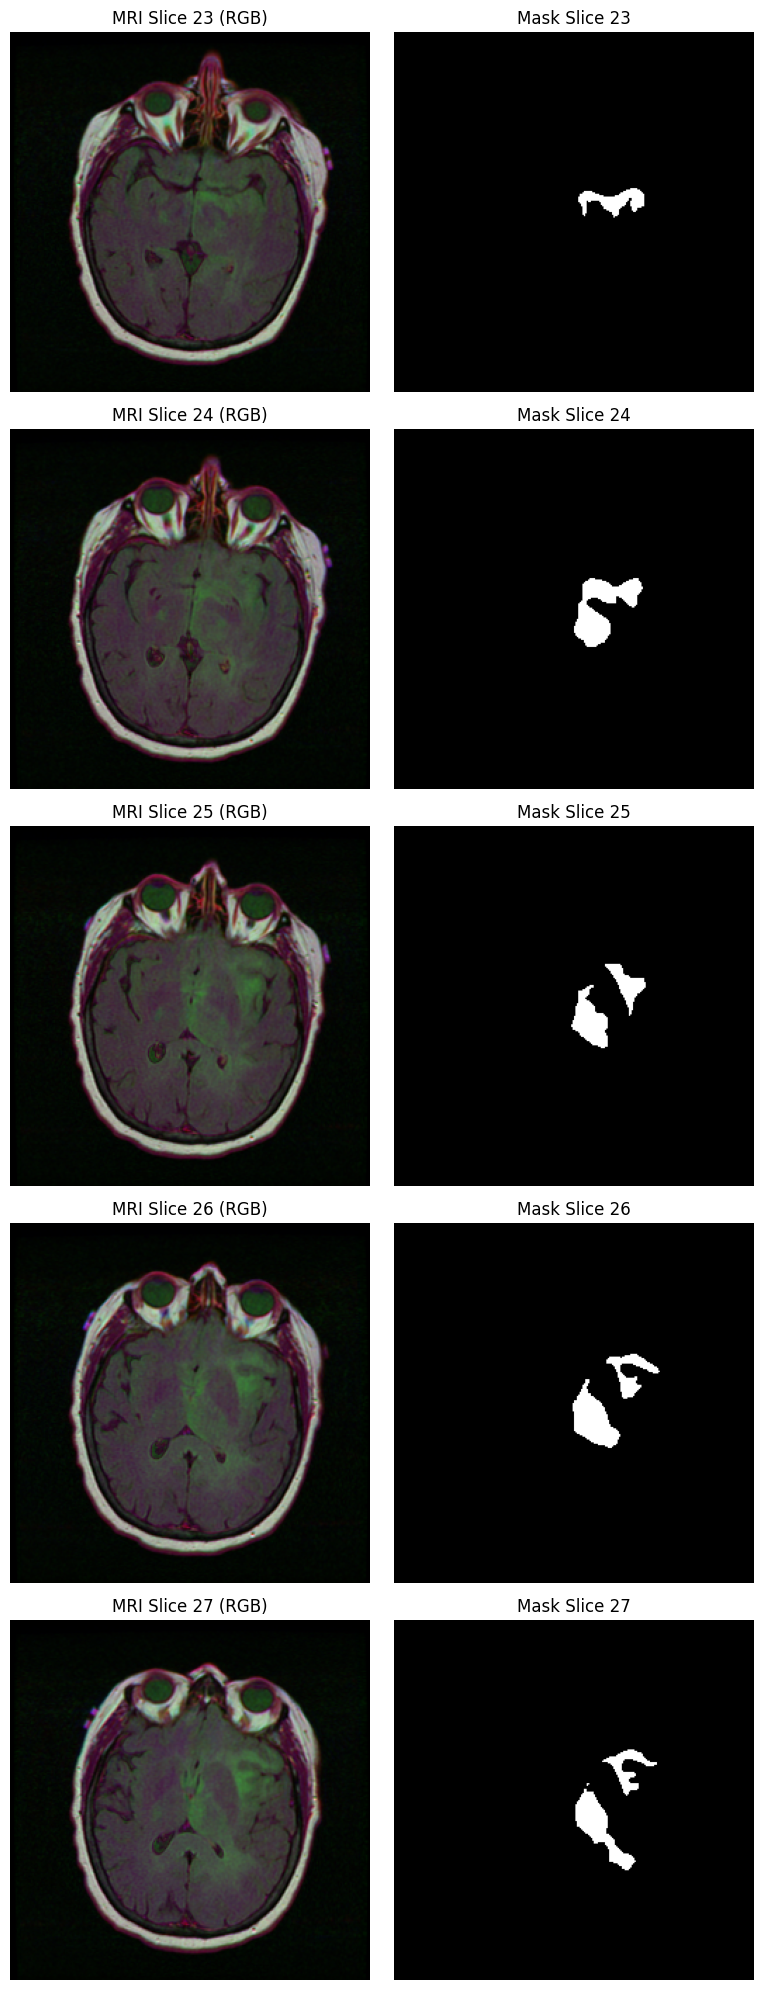

In [9]:
def plot_patient_mri_slices(patient_idx, slice_idxs=None, nrows=5, shuffle=True, separate_channels=False):
    random.seed(42)
    
    p_slices, p_masks = pw_mri_ds[patient_idx]
    
    if slice_idxs is None:
        slice_idxs = list(range(p_slices.shape[0]))
    else:
        slice_idxs = list(slice_idxs)
        
    if not slice_idxs:
        print(f"No slices found to plot for patient {patient_idx}.")
        return

    nrows = min(len(slice_idxs), nrows)

    if shuffle:
        slice_idxs = random.sample(slice_idxs, nrows)
    else:
        slice_idxs = slice_idxs[:nrows]

    # 4 columns for separated sequences + mask; 2 columns for RGB composite + mask
    ncols = 4 if separate_channels else 2
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4), squeeze=False)

    for ax_idx, slice_idx in enumerate(slice_idxs):
        p_slice = p_slices[slice_idx]
        p_mask  = p_masks[slice_idx]

        if separate_channels:
            axes[ax_idx, 0].imshow(p_slice[0].cpu().numpy(), cmap="gray")
            axes[ax_idx, 0].set_title(f"Slice {slice_idx}: Pre-Contrast")
            
            axes[ax_idx, 1].imshow(p_slice[1].cpu().numpy(), cmap="gray")
            axes[ax_idx, 1].set_title(f"Slice {slice_idx}: FLAIR")
            
            axes[ax_idx, 2].imshow(p_slice[2].cpu().numpy(), cmap="gray")
            axes[ax_idx, 2].set_title(f"Slice {slice_idx}: Post-Contrast")
            
            axes[ax_idx, 3].imshow(p_mask[0].cpu().numpy(), cmap="gray")
            axes[ax_idx, 3].set_title(f"Slice {slice_idx}: Mask")
        else:
            rgb_img = p_slice.permute(1, 2, 0).cpu().numpy()
            axes[ax_idx, 0].imshow(rgb_img)
            axes[ax_idx, 0].set_title(f"MRI Slice {slice_idx} (RGB)")
            
            axes[ax_idx, 1].imshow(p_mask[0].cpu().numpy(), cmap="gray")
            axes[ax_idx, 1].set_title(f"Mask Slice {slice_idx}")

        for col in range(ncols):
            axes[ax_idx, col].axis("off")

    plt.tight_layout()
    plt.show()

plot_patient_mri_slices(0, slice_idxs=p_stats["tumour_mask"], shuffle=False)

In [10]:
missing_stats = {
    # Sequence Replication (Substituted by FLAIR)
    "pre_missing_case": set(),
    "post_missing_case": set(),
    "both_missing_case": set(),
    
    "has_empty_pre_slices": set(),
    "has_empty_flair_slices": set(),
    "has_empty_post_slices": set(),
    "has_empty_background_slices": set(),
}

all_patient_stats = []

pbar = tqdm(range(len(pw_mri_ds)), desc="Calculating Patient-wise stats")
for patient_idx in pbar:
    p_slices, p_masks = pw_mri_ds[patient_idx]
    p_stats = calc_stats(p_slices, p_masks, show_progress=False)
    all_patient_stats.append(p_stats)

    is_both = len(p_stats["both_missing"]) > 0
    is_pre  = len(p_stats["pre_missing"]) > 0
    is_post = len(p_stats["post_missing"]) > 0

    if is_both:
        missing_stats["both_missing_case"].add(patient_idx)
    elif is_pre:
        missing_stats["pre_missing_case"].add(patient_idx)
    elif is_post:
        missing_stats["post_missing_case"].add(patient_idx)

    if len(p_stats["empty_pre"]) > 0:
        missing_stats["has_empty_pre_slices"].add(patient_idx)
    if len(p_stats["empty_flair"]) > 0:
        missing_stats["has_empty_flair_slices"].add(patient_idx)
    if len(p_stats["empty_post"]) > 0:
        missing_stats["has_empty_post_slices"].add(patient_idx)
    if len(p_stats["empty_background"]) > 0:
        missing_stats["has_empty_background_slices"].add(patient_idx)

print("--- Sequence Replication (Substituted by FLAIR) ---")
print(f"Pre-contrast only missing cases : {len(missing_stats['pre_missing_case'])}")
print(f"Post-contrast only missing cases: {len(missing_stats['post_missing_case'])}")
print(f"Both sequences missing cases    : {len(missing_stats['both_missing_case'])}")

print("\n--- Physical Channel Emptiness (max == 0) ---")
print(f"Cases with empty Pre-contrast slices : {len(missing_stats['has_empty_pre_slices'])}")
print(f"Cases with empty FLAIR slices        : {len(missing_stats['has_empty_flair_slices'])}")
print(f"Cases with empty Post-contrast slices: {len(missing_stats['has_empty_post_slices'])}")
print(f"Cases with completely black slices   : {len(missing_stats['has_empty_background_slices'])}")

Calculating Patient-wise stats:   0%|          | 0/110 [00:00<?, ?it/s]

--- Sequence Replication (Substituted by FLAIR) ---
Pre-contrast only missing cases : 12
Post-contrast only missing cases: 0
Both sequences missing cases    : 6

--- Physical Channel Emptiness (max == 0) ---
Cases with empty Pre-contrast slices : 25
Cases with empty FLAIR slices        : 20
Cases with empty Post-contrast slices: 2
Cases with completely black slices   : 0


## Cases with missing pre-constrast slices but not empty pre-constract slices

In [11]:
pre_missing_no_empty_slices_cases = missing_stats["pre_missing_case"] - missing_stats["has_empty_pre_slices"]

for patient_idx in pre_missing_no_empty_slices_cases:
    p_stats = all_patient_stats[patient_idx]
    print(f"Patient Idx {patient_idx}:")
    print(f"\tPre-Contrast missing in {len(p_stats["pre_missing"])} images")
    print(f"\tBoth missing in {len(p_stats["both_missing"])} images")
    print()

Patient Idx 16:
	Pre-Contrast missing in 35 images
	Both missing in 0 images

Patient Idx 75:
	Pre-Contrast missing in 58 images
	Both missing in 0 images

Patient Idx 68:
	Pre-Contrast missing in 27 images
	Both missing in 0 images

Patient Idx 92:
	Pre-Contrast missing in 36 images
	Both missing in 0 images



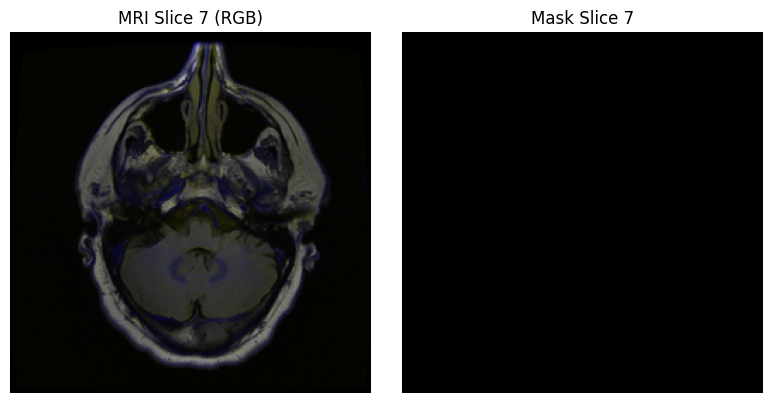

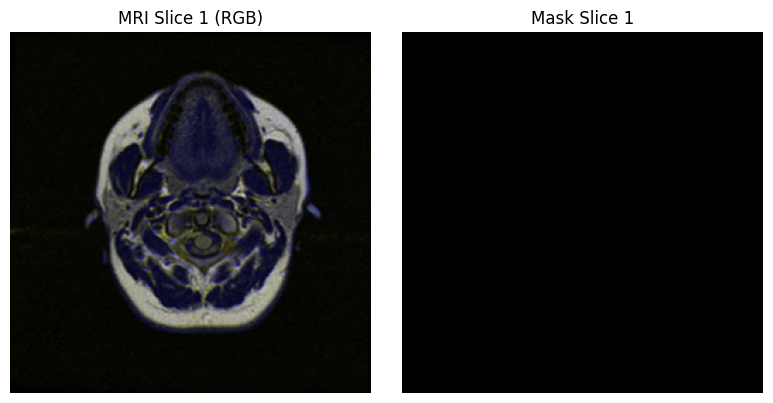

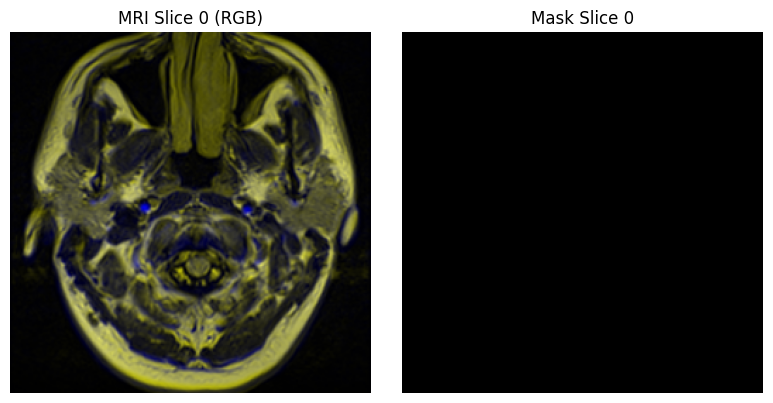

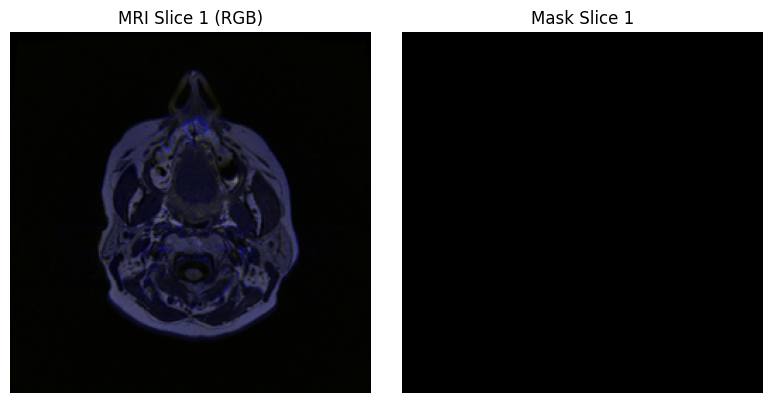

In [12]:
def plot_patient_sequences(patient_idx, slice_idxs, ch1=0, ch2=1):
    p_slices, p_masks = pw_mri_ds[patient_idx]

    nrows = len(slice_idxs)
    fig, axes = plt.subplots(nrows,2,figsize=(10,nrows*5))

    if nrows == 1:
        axes = [axes]

    for ax_idx, slice_idx in enumerate(slice_idxs):        
        pre_contrast = p_slices[slice_idx][ch1]
        flair        = p_slices[slice_idx][ch2]
        
        axes[ax_idx][0].imshow(pre_contrast, cmap="gray")
        axes[ax_idx][1].imshow(flair, cmap="gray")

        axes[ax_idx][0].axis("off")
        axes[ax_idx][1].axis("off")

        axes[ax_idx][0].set_title(f"Pre-Constrast slice {slice_idx}")
        axes[ax_idx][1].set_title(f"FLAIR for slice {slice_idx}")

    plt.show()

random.seed(42)

for patient_idx in pre_missing_no_empty_slices_cases:
    pre_missing_idx = all_patient_stats[patient_idx]["pre_missing"]
    pre_missing_idx = [random.choice(pre_missing_idx) for _ in range(1)]
    plot_patient_mri_slices(patient_idx, pre_missing_idx)

## Cases with no missing sequences across all slices

In [13]:
contains_empty_seqs = missing_stats["has_empty_pre_slices"].union(missing_stats["has_empty_flair_slices"]).union(missing_stats["has_empty_post_slices"])
contains_all_seqs   = list(set(range(len(pw_mri_ds))) - contains_empty_seqs)

In [14]:
p_slices, p_masks = pw_mri_ds[contains_all_seqs[0]]
p_stats = calc_stats(p_slices, p_masks)

print(f"Empty mask in {len(p_stats['empty_mask'])} images")
print(f"Tumour mask in {len(p_stats['tumour_mask'])} images")

print()

print(f"Empty background (all channels 0) in {len(p_stats['empty_background'])} images")

print(f"Empty Pre-Contrast sequence in {len(p_stats['empty_pre'])} images")
print(f"Empty FLAIR sequence in {len(p_stats['empty_flair'])} images")
print(f"Empty Post-Contrast sequence in {len(p_stats['empty_post'])} images")

print()

print(f"Pre-Contrast missing (replicated FLAIR) in {len(p_stats['pre_missing'])} images")
print(f"Post-Contrast missing (replicated FLAIR) in {len(p_stats['post_missing'])} images")
print(f"Both missing (replicated FLAIR) in {len(p_stats['both_missing'])} images")
print(f"All sequences present in {len(p_stats['all_present'])} images")

Calculating image stats:   0%|          | 0/58 [00:00<?, ?it/s]

Empty mask in 31 images
Tumour mask in 27 images

Empty background (all channels 0) in 0 images
Empty Pre-Contrast sequence in 0 images
Empty FLAIR sequence in 0 images
Empty Post-Contrast sequence in 0 images

Pre-Contrast missing (replicated FLAIR) in 0 images
Post-Contrast missing (replicated FLAIR) in 0 images
Both missing (replicated FLAIR) in 0 images
All sequences present in 58 images


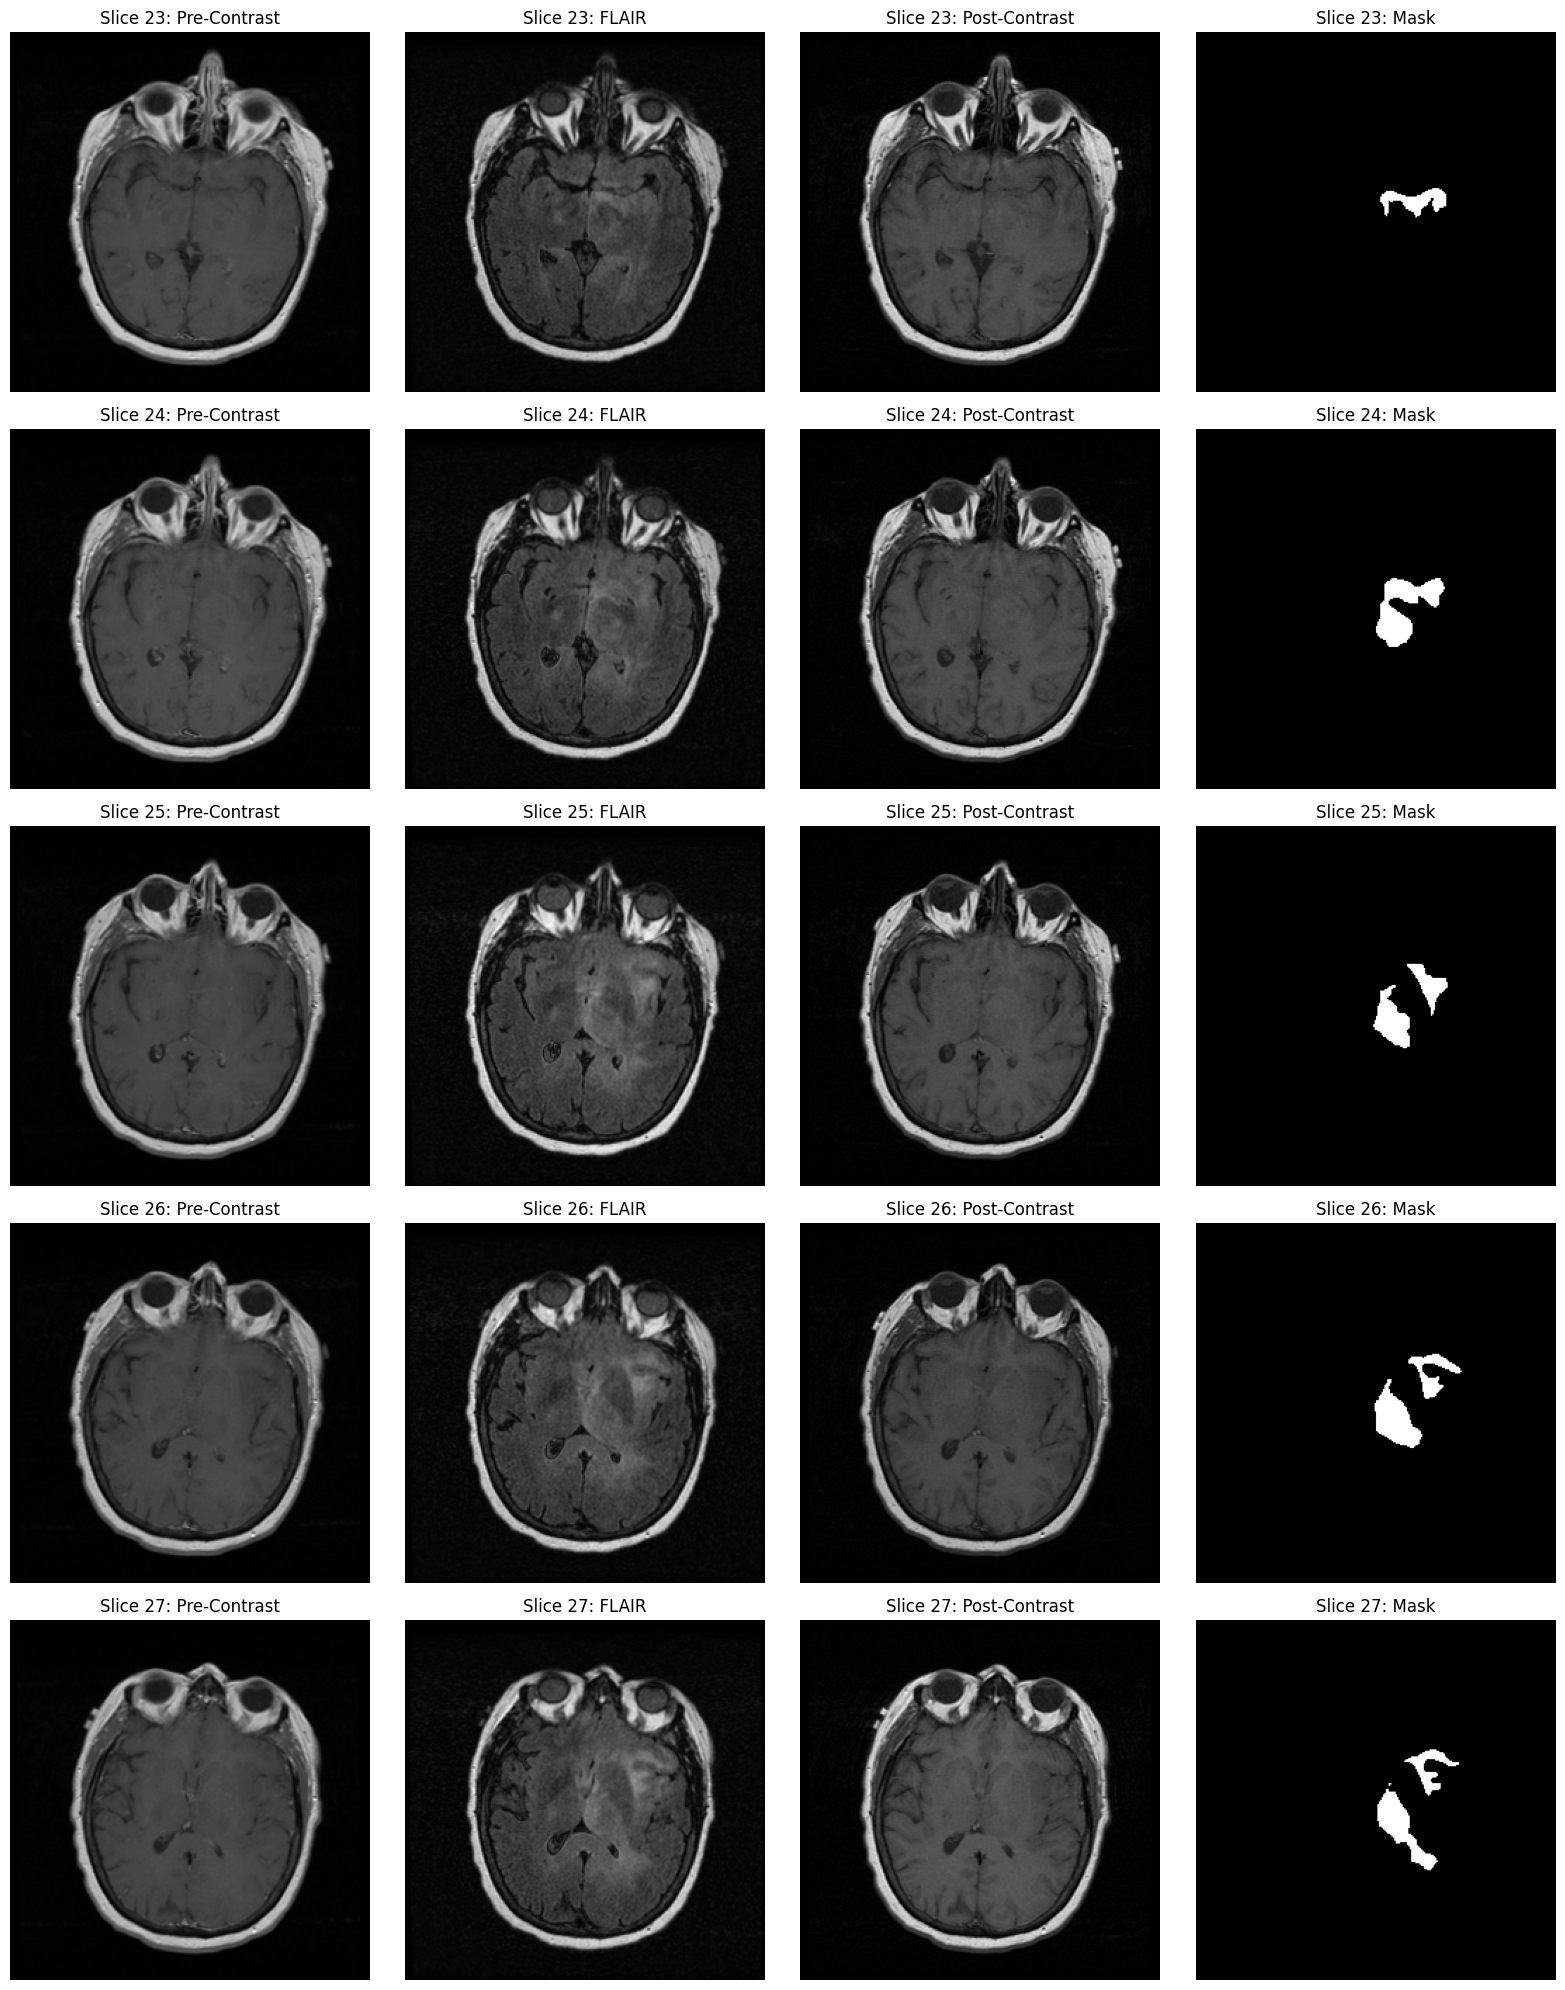

In [15]:
plot_patient_mri_slices(0, slice_idxs=p_stats["tumour_mask"], shuffle=False, separate_channels=True)

## Dataset subset of all slices with all channels and segmentation mask

In [16]:
class CleanSlicesMRIDataset(Dataset):
    def __init__(self):
        self.indices = []

        for patient_idx in contains_all_seqs:
            for slice_idx in all_patient_stats[patient_idx]["tumour_mask"]:
                self.indices.append((patient_idx, slice_idx))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        patient_idx, slice_idx = self.indices[idx]
        mri_slice, mask = pw_mri_ds[patient_idx]
        return mri_slice[slice_idx], mask[slice_idx]

In [17]:
clean_slices_mri_ds = CleanSlicesMRIDataset()
mri_slice, mask     = clean_slices_mri_ds[0]